# Teaching a Vision Model to Say "I Don't Know"

Vision models confidently mislabel things they were never trained on. This notebook trains a small classifier on CIFAR-10, then tests whether its confidence can flag unfamiliar images: SVHN digits and my own phone photos. It compares the standard softmax confidence with the energy score (Liu et al., NeurIPS 2020).

## 1. Setup

In [4]:
import os, glob, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

In [5]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [6]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device, "-", torch.cuda.get_device_name(0) if device == "cuda" else "no GPU")

from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/ood_project"
MODEL_PATH = os.path.join(PROJECT_DIR, "small_cnn_cifar10_seed42.pth")
PHOTO_DIR = os.path.join(PROJECT_DIR, "my_photos")

Using: cuda - Tesla T4
Mounted at /content/drive


## 2. Data
CIFAR-10 is what the model learns (10 classes). SVHN house-number digits are the unfamiliar images it has never seen.

In [7]:
transform = transforms.ToTensor()

train_set = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
test_set = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)
svhn_set = torchvision.datasets.SVHN(root="./data", split="test", download=True, transform=transform)

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
test_loader = DataLoader(test_set, batch_size=64, shuffle=False)
svhn_loader = DataLoader(svhn_set, batch_size=64, shuffle=False)

print(f"CIFAR-10 train: {len(train_set)} | CIFAR-10 test: {len(test_set)} | SVHN: {len(svhn_set)}")

100%|██████████| 170M/170M [00:43<00:00, 3.95MB/s]
100%|██████████| 64.3M/64.3M [00:01<00:00, 53.4MB/s]


CIFAR-10 train: 50000 | CIFAR-10 test: 10000 | SVHN: 26032


## 3. Model
A small CNN: two pattern-finding layers, then two layers that turn patterns into 10 class scores.

In [8]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),                              # 32x32 -> 16x16
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),                              # 16x16 -> 8x8
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = SmallCNN().to(device)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Parameters: 545098


## 4. Training
Trains for 10 epochs (about 3 minutes on a T4 GPU) and saves the model to Google Drive. If a saved model already exists, it loads it instead of retraining.

In [9]:
if os.path.exists(MODEL_PATH):
    model.load_state_dict(torch.load(MODEL_PATH))
    print("Loaded saved model from", MODEL_PATH)
else:
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    num_epochs = 10

    for epoch in range(num_epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        print(f"Epoch {epoch+1}/{num_epochs}  loss: {running_loss/len(train_loader):.3f}  "
              f"train accuracy: {100*correct/total:.1f}%")

    os.makedirs(PROJECT_DIR, exist_ok=True)
    torch.save(model.state_dict(), MODEL_PATH)
    print("Saved model to", MODEL_PATH)

Loaded saved model from /content/drive/MyDrive/ood_project/small_cnn_cifar10_seed42.pth


## 5. Test accuracy
How well the model does on 10,000 CIFAR-10 images it never trained on.

In [10]:
def accuracy(loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            correct += (model(images).argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return 100 * correct / total

print(f"Test accuracy: {accuracy(test_loader):.1f}%")

Test accuracy: 72.1%


## 6. Can confidence flag unfamiliar images? (SVHN)
Two ways to read the model's output:
- **Softmax confidence:** the top percentage after softmax (the standard baseline).
- **Energy score:** `logsumexp` of the raw scores (Liu et al., 2020). It keeps how strong the raw scores are, which softmax throws away.

For both, higher should mean "familiar". Scored with **AUROC** (how often a random familiar image beats a random unfamiliar one; higher is better) and **FPR95** (share of unfamiliar images that sneak through when 95% of familiar images are kept; lower is better).

In [11]:
def get_logits(loader):
    model.eval()
    out = []
    with torch.no_grad():
        for images, _ in loader:
            out.append(model(images.to(device)).cpu())
    return torch.cat(out)

def softmax_conf(logits):
    return F.softmax(logits, dim=1).max(dim=1).values

def energy_score(logits):
    return torch.logsumexp(logits, dim=1)

def ood_scores(familiar, unfamiliar):
    familiar, unfamiliar = familiar.numpy(), unfamiliar.numpy()
    all_scores = np.concatenate([familiar, unfamiliar])
    is_familiar = np.concatenate([np.ones(len(familiar)), np.zeros(len(unfamiliar))])
    auroc = roc_auc_score(is_familiar, all_scores)
    fpr95 = (unfamiliar >= np.percentile(familiar, 5)).mean()
    return auroc, fpr95

FIG_DIR = os.path.join(PROJECT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

Average softmax confidence: CIFAR-10 81.1%  |  SVHN 58.2%
SVHN images over 90% confident: 3.7%


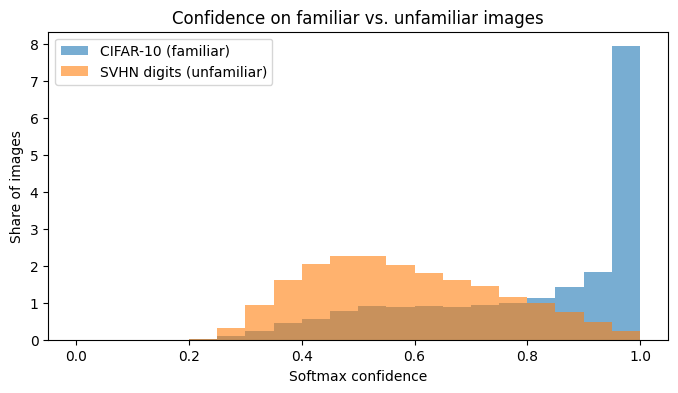

In [12]:
cifar_logits = get_logits(test_loader)
svhn_logits = get_logits(svhn_loader)

cifar_conf, svhn_conf = softmax_conf(cifar_logits), softmax_conf(svhn_logits)
print(f"Average softmax confidence: CIFAR-10 {cifar_conf.mean()*100:.1f}%  |  SVHN {svhn_conf.mean()*100:.1f}%")
print(f"SVHN images over 90% confident: {(svhn_conf > 0.9).float().mean()*100:.1f}%")

plt.figure(figsize=(8, 4))
plt.hist(cifar_conf.numpy(), bins=20, range=(0, 1), alpha=0.6, density=True, label="CIFAR-10 (familiar)")
plt.hist(svhn_conf.numpy(), bins=20, range=(0, 1), alpha=0.6, density=True, label="SVHN digits (unfamiliar)")
plt.xlabel("Softmax confidence")
plt.ylabel("Share of images")
plt.title("Confidence on familiar vs. unfamiliar images")
plt.legend()
plt.savefig(os.path.join(FIG_DIR, "confidence_cifar_vs_svhn.png"), dpi=150, bbox_inches="tight")
plt.show()

In [13]:
for cutoff in [0.5, 0.7, 0.9]:
    print(f"Cutoff {cutoff:.0%}:  SVHN caught {(svhn_conf < cutoff).float().mean()*100:5.1f}%  |  "
          f"CIFAR false alarms {(cifar_conf < cutoff).float().mean()*100:5.1f}%")
print()

svhn_soft = ood_scores(cifar_conf, svhn_conf)
svhn_energy = ood_scores(energy_score(cifar_logits), energy_score(svhn_logits))

print(f"{'SVHN':<22}{'AUROC':>10}{'FPR95':>10}")
print(f"{'Softmax (baseline)':<22}{svhn_soft[0]*100:>9.1f}%{svhn_soft[1]*100:>9.1f}%")
print(f"{'Energy':<22}{svhn_energy[0]*100:>9.1f}%{svhn_energy[1]*100:>9.1f}%")

Cutoff 50%:  SVHN caught  36.1%  |  CIFAR false alarms  10.8%
Cutoff 70%:  SVHN caught  74.6%  |  CIFAR false alarms  28.8%
Cutoff 90%:  SVHN caught  96.3%  |  CIFAR false alarms  51.2%

SVHN                       AUROC     FPR95
Softmax (baseline)         80.5%     81.6%
Energy                     78.7%     92.9%


### Is the difference consistent? (5 training runs)
One run can mislead, so the model is retrained with 5 different seeds and both methods are scored each time.

In [14]:
RESULTS_PATH = os.path.join(PROJECT_DIR, "five_run_results.npy")

if os.path.exists(RESULTS_PATH):
    r = np.load(RESULTS_PATH)
    print("Loaded saved 5-run results from", RESULTS_PATH)
else:
    results = []
    for s in [0, 1, 2, 3, 4]:
        random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

        m = SmallCNN().to(device)
        opt = optim.Adam(m.parameters(), lr=0.001)
        crit = nn.CrossEntropyLoss()
        for epoch in range(10):
            m.train()
            for images, labels in train_loader:
                images, labels = images.to(device), labels.to(device)
                opt.zero_grad()
                crit(m(images), labels).backward()
                opt.step()

        m.eval()
        with torch.no_grad():
            cl = torch.cat([m(x.to(device)).cpu() for x, _ in test_loader])
            sl = torch.cat([m(x.to(device)).cpu() for x, _ in svhn_loader])

        acc = (cl.argmax(dim=1) == torch.tensor(test_set.targets)).float().mean().item() * 100
        sa, sf = ood_scores(softmax_conf(cl), softmax_conf(sl))
        ea, ef = ood_scores(energy_score(cl), energy_score(sl))
        results.append([acc, sa * 100, sf * 100, ea * 100, ef * 100])
        print(f"Seed {s}: test acc {acc:.1f}% | softmax AUROC {sa*100:.1f}%, FPR95 {sf*100:.1f}% | "
              f"energy AUROC {ea*100:.1f}%, FPR95 {ef*100:.1f}%")

    r = np.array(results)
    np.save(RESULTS_PATH, r)
    print("Saved 5-run results to", RESULTS_PATH)

names = ["Test accuracy", "Softmax AUROC", "Softmax FPR95", "Energy AUROC", "Energy FPR95"]
print("\nAverage over 5 runs (± spread):")
for i, name in enumerate(names):
    print(f"  {name:<15} {r[:, i].mean():.1f}% ± {r[:, i].std():.1f}")

Seed 0: test acc 71.2% | softmax AUROC 80.5%, FPR95 81.2% | energy AUROC 81.4%, FPR95 88.1%
Seed 1: test acc 71.6% | softmax AUROC 80.7%, FPR95 81.7% | energy AUROC 82.0%, FPR95 89.0%
Seed 2: test acc 71.7% | softmax AUROC 80.8%, FPR95 79.0% | energy AUROC 85.1%, FPR95 80.7%
Seed 3: test acc 71.0% | softmax AUROC 80.4%, FPR95 79.9% | energy AUROC 77.0%, FPR95 95.4%
Seed 4: test acc 69.2% | softmax AUROC 77.3%, FPR95 86.4% | energy AUROC 80.3%, FPR95 89.8%
Saved 5-run results to /content/drive/MyDrive/ood_project/five_run_results.npy

Average over 5 runs (± spread):
  Test accuracy   70.9% ± 0.9
  Softmax AUROC   79.9% ± 1.3
  Softmax FPR95   81.6% ± 2.6
  Energy AUROC    81.2% ± 2.6
  Energy FPR95    88.6% ± 4.7


## 7. Real-world test: my own phone photos
16 photos of CIFAR-10 classes (familiar) and 18 everyday objects (unfamiliar), taken mostly on my phone, scored with the seed-42 model.

In [15]:
!pip install pillow-heif -q
from pillow_heif import register_heif_opener
from PIL import Image, ImageOps
register_heif_opener()

In [16]:
prep = transforms.Compose([transforms.Resize(32), transforms.CenterCrop(32), transforms.ToTensor()])

def load_folder(folder):
    paths = sorted(glob.glob(os.path.join(PHOTO_DIR, folder, "*")))
    images, names = [], []
    for p in paths:
        try:
            img = ImageOps.exif_transpose(Image.open(p)).convert("RGB")
        except Exception as e:
            print("Skipped", os.path.basename(p), "-", e)
            continue
        images.append(prep(img))
        names.append(os.path.basename(p))
    return torch.stack(images), names

familiar_imgs, familiar_names = load_folder("familiar")
unfamiliar_imgs, unfamiliar_names = load_folder("unfamiliar")
print("Familiar:", familiar_imgs.shape[0], "| Unfamiliar:", unfamiliar_imgs.shape[0])

Familiar: 16 | Unfamiliar: 18


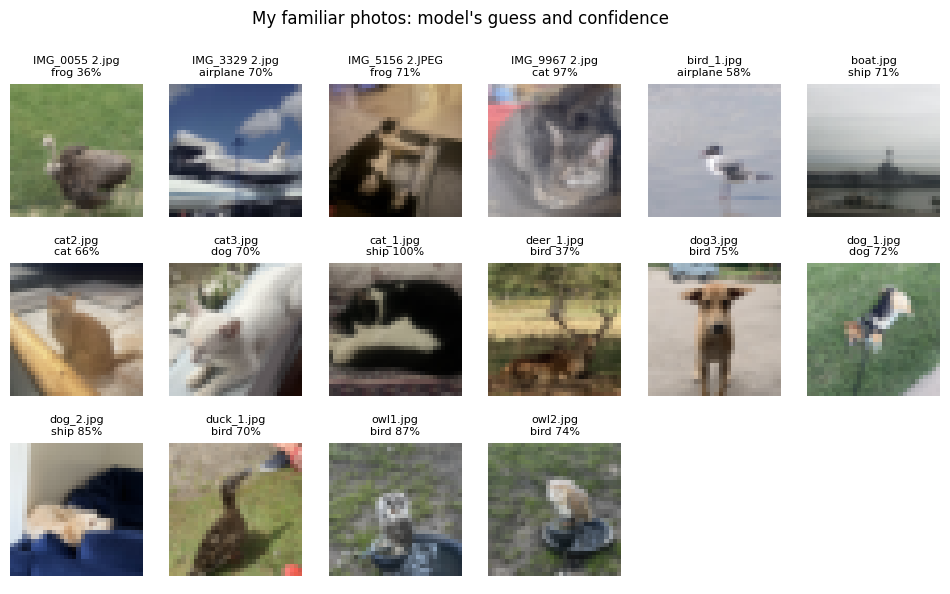

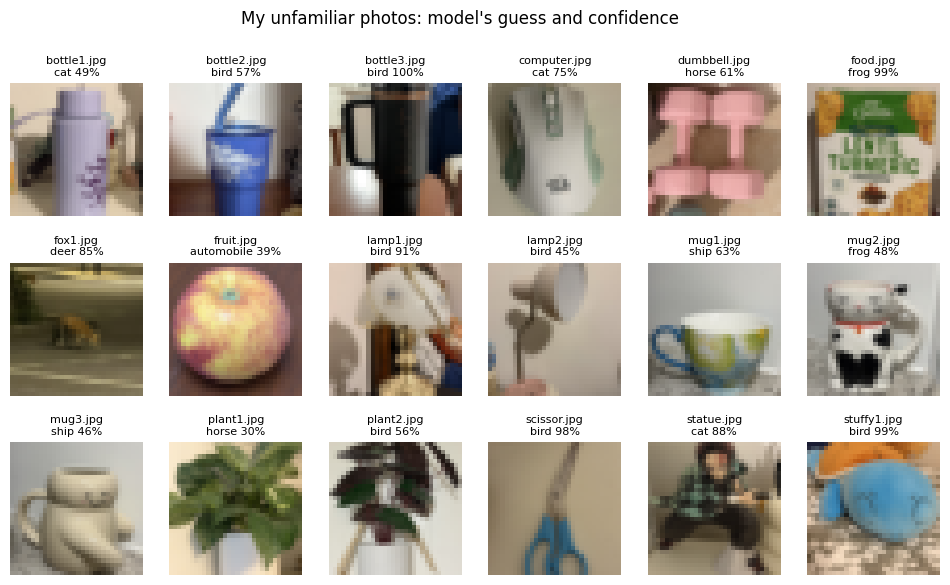

In [17]:
def show_grid(imgs, titles, title, filename):
    cols = 6
    rows = (len(imgs) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2, rows * 2.2))
    for ax in axes.flat:
        ax.axis("off")
    for i in range(len(imgs)):
        axes.flat[i].imshow(imgs[i].permute(1, 2, 0))
        axes.flat[i].set_title(titles[i], fontsize=8)
    fig.suptitle(title)
    plt.savefig(os.path.join(FIG_DIR, filename), dpi=150, bbox_inches="tight")
    plt.show()

model.eval()
with torch.no_grad():
    fam_logits = model(familiar_imgs.to(device)).cpu()
    unf_logits = model(unfamiliar_imgs.to(device)).cpu()

def titles_with_guesses(names, logits):
    conf, pred = F.softmax(logits, dim=1).max(dim=1)
    return [f"{n}\n{train_set.classes[p]} {c*100:.0f}%" for n, p, c in zip(names, pred, conf)]

show_grid(familiar_imgs, titles_with_guesses(familiar_names, fam_logits),
          "My familiar photos: model's guess and confidence", "my_photos_familiar.png")
show_grid(unfamiliar_imgs, titles_with_guesses(unfamiliar_names, unf_logits),
          "My unfamiliar photos: model's guess and confidence", "my_photos_unfamiliar.png")

In [18]:
photo_soft = ood_scores(softmax_conf(fam_logits), softmax_conf(unf_logits))
photo_energy = ood_scores(energy_score(fam_logits), energy_score(unf_logits))

print(f"Average softmax confidence: familiar {softmax_conf(fam_logits).mean()*100:.1f}%  |  "
      f"unfamiliar {softmax_conf(unf_logits).mean()*100:.1f}%")
print(f"Softmax: AUROC {photo_soft[0]*100:.1f}%, FPR95 {photo_soft[1]*100:.1f}%")
print(f"Energy:  AUROC {photo_energy[0]*100:.1f}%, FPR95 {photo_energy[1]*100:.1f}%")

Average softmax confidence: familiar 71.1%  |  unfamiliar 68.2%
Softmax: AUROC 54.2%, FPR95 94.4%
Energy:  AUROC 62.8%, FPR95 61.1%


## 8. Summary

In [21]:
def pct(x):
    return f"{x*100:.1f}%"

print("| Test | Softmax AUROC ↑ | Energy AUROC ↑ | Softmax FPR95 ↓ | Energy FPR95 ↓ |")
print("|---|---|---|---|---|")
print(f"| SVHN digits (seed 42) | {pct(svhn_soft[0])} | {pct(svhn_energy[0])} | {pct(svhn_soft[1])} | {pct(svhn_energy[1])} |")
print(f"| SVHN digits (5 runs, avg ± spread) | {r[:,1].mean():.1f}% ± {r[:,1].std():.1f} | {r[:,3].mean():.1f}% ± {r[:,3].std():.1f} "
      f"| {r[:,2].mean():.1f}% ± {r[:,2].std():.1f} | {r[:,4].mean():.1f}% ± {r[:,4].std():.1f} |")
print(f"| My phone photos (seed 42) | {pct(photo_soft[0])} | {pct(photo_energy[0])} | {pct(photo_soft[1])} | {pct(photo_energy[1])} |")

| Test | Softmax AUROC ↑ | Energy AUROC ↑ | Softmax FPR95 ↓ | Energy FPR95 ↓ |
|---|---|---|---|---|
| SVHN digits (seed 42) | 80.5% | 78.7% | 81.6% | 92.9% |
| SVHN digits (5 runs, avg ± spread) | 79.9% ± 1.3 | 81.2% ± 2.6 | 81.6% ± 2.6 | 88.6% ± 4.7 |
| My phone photos (seed 42) | 54.2% | 62.8% | 94.4% | 61.1% |
